# Clase práctica: K-means (método del codo) y clustering jerárquico

**Objetivos**

1. Preparar un conjunto de datos para clustering (escalamiento).
2. Elegir *k* en K-means con el **método del codo** (y contrastarlo con la silueta).
3. Construir el **clustering jerárquico** (enlaces y dendrograma).
4. Visualizar y comparar ambos resultados.

> El clustering es no supervisado: las etiquetas reales (si existen) **no** se usan para agrupar, solo para interpretar al final.

**Cómo usar el notebook con tus propios datos:** cambia la celda de carga (sección 1) para leer un CSV y define `X` (solo columnas numéricas) y, opcionalmente, `y_real`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

sns.set_theme(style='whitegrid')
SEED = 42

## 1. Datos

Usamos el dataset *Wine* (178 vinos, 13 mediciones químicas). Para usar un CSV propio, por ejemplo:

```python
df = pd.read_csv('ejercicios/data/peptides.csv')
y_real = df['Class']
X = df.drop(columns='Class').select_dtypes('number')
```

In [3]:
wine = load_wine(as_frame=True)
X = wine.data
y_real = wine.target          # solo para interpretar al final
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
print(X.shape)
print('Valores faltantes:', int(X.isna().sum().sum()))
X.describe().T[['mean', 'std', 'min', 'max']]

(178, 13)
Valores faltantes: 0


,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


**Pregunta 1.** ¿Por qué las escalas tan distintas (p. ej. `proline` vs `hue`) son un problema para K-means y para la distancia euclidiana?

## 2. Escalamiento

K-means y los métodos jerárquicos con distancia euclidiana dependen de la escala. Estandarizamos (media 0, desviación 1).

In [5]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
Xs = pd.DataFrame(Xs, columns=X.columns, index=X.index)
Xs.describe().T[['mean', 'std']].round(2).head()

,mean,std
alcohol,-0.0,1.0
malic_acid,-0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,-0.0,1.0
magnesium,-0.0,1.0


## 3. K-means y método del codo

Para cada *k* calculamos la **inercia** (WCSS: suma de distancias cuadradas de cada punto a su centroide). La inercia siempre baja al aumentar *k*; buscamos el "codo" donde la mejora deja de ser sustancial.

Para elegirlo de forma objetiva usamos la distancia máxima de cada punto de la curva a la recta que une el primer y el último punto.

k sugerido por el codo: 3


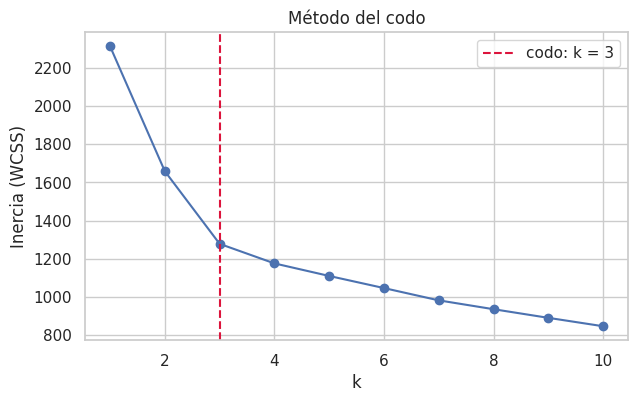

In [6]:
ks = range(1, 11)
inercias = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    inercias.append(km.inertia_)
inercias = np.array(inercias)


def punto_codo(ks, y):
    # Distancia de cada punto a la recta entre los extremos (curva normalizada)
    x = np.array(list(ks), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    d = np.abs(yn + xn - 1) / np.sqrt(2)   # la recta es yn = 1 - xn
    return int(x[np.argmax(d)])


k_codo = punto_codo(ks, inercias)
print('k sugerido por el codo:', k_codo)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(ks), inercias, 'o-')
ax.axvline(k_codo, color='crimson', ls='--', label=f'codo: k = {k_codo}')
ax.set(xlabel='k', ylabel='Inercia (WCSS)', title='Método del codo')
ax.legend()
plt.show()

### Verificación con el coeficiente de silueta

El codo es una regla visual y a veces ambigua. La silueta (−1 a 1; más alta = grupos más compactos y separados) sirve como segunda opinión.

k con mayor silueta: 3


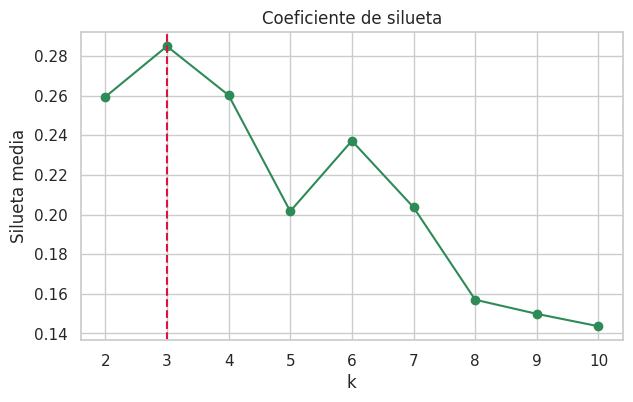

In [7]:
sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs)
    sil[k] = silhouette_score(Xs, labels)

k_sil = max(sil, key=sil.get)
print('k con mayor silueta:', k_sil)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(sil), list(sil.values()), 'o-', color='seagreen')
ax.axvline(k_sil, color='crimson', ls='--')
ax.set(xlabel='k', ylabel='Silueta media', title='Coeficiente de silueta')
plt.show()

**Pregunta 2.** ¿Coinciden el codo y la silueta? Si no, ¿qué *k* elegirías y con qué argumento (interpretabilidad, pregunta científica)?

In [8]:
K = k_codo   # puedes sobrescribirlo con tu decisión, p. ej. K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs)
X_km = X.assign(cluster_kmeans=kmeans.labels_)
X_km.groupby('cluster_kmeans').size().rename('n')

,n
cluster_kmeans,
0,65
1,51
2,62


### Perfil de cada cluster (medias de las variables estandarizadas)

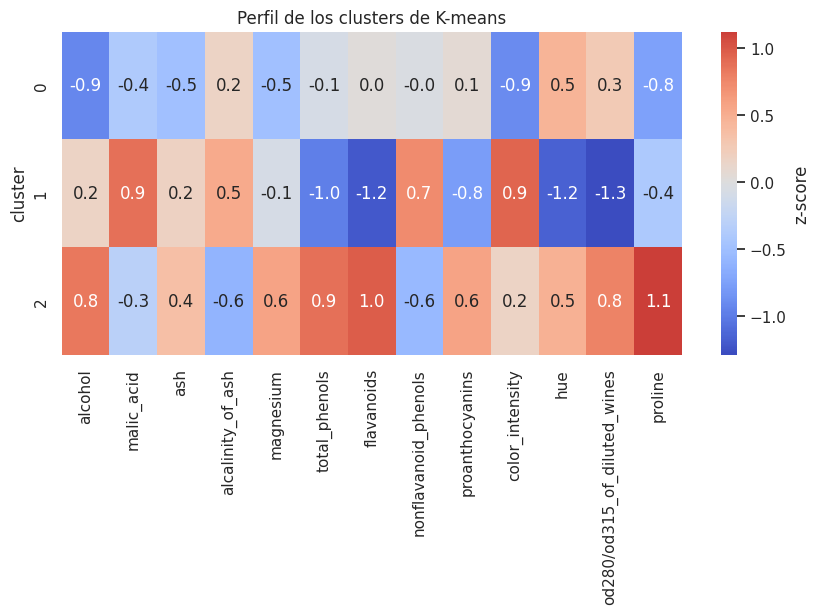

In [9]:
perfil = Xs.assign(cluster=kmeans.labels_).groupby('cluster').mean()
plt.figure(figsize=(10, 3 + 0.4 * K))
sns.heatmap(perfil, cmap='coolwarm', center=0, annot=True, fmt='.1f', cbar_kws={'label': 'z-score'})
plt.title('Perfil de los clusters de K-means')
plt.show()

## 4. Clustering jerárquico aglomerativo

Se parte de cada observación como un grupo y se fusionan los más cercanos. El resultado se representa con un **dendrograma**; la altura de cada unión indica la distancia a la que se fusionaron.

Comparamos enlaces con el **coeficiente cofenético** (qué tan fielmente el dendrograma conserva las distancias originales; más cercano a 1 es mejor).

In [10]:
dist = pdist(Xs, metric='euclidean')
enlaces = {}
for metodo in ['single', 'complete', 'average', 'ward']:
    Z = linkage(Xs, method=metodo)
    enlaces[metodo] = Z
    c, _ = cophenet(Z, dist)
    print(f'{metodo:9s} cofenético = {c:.3f}')

single    cofenético = 0.544
complete  cofenético = 0.592
average   cofenético = 0.759
ward      cofenético = 0.662


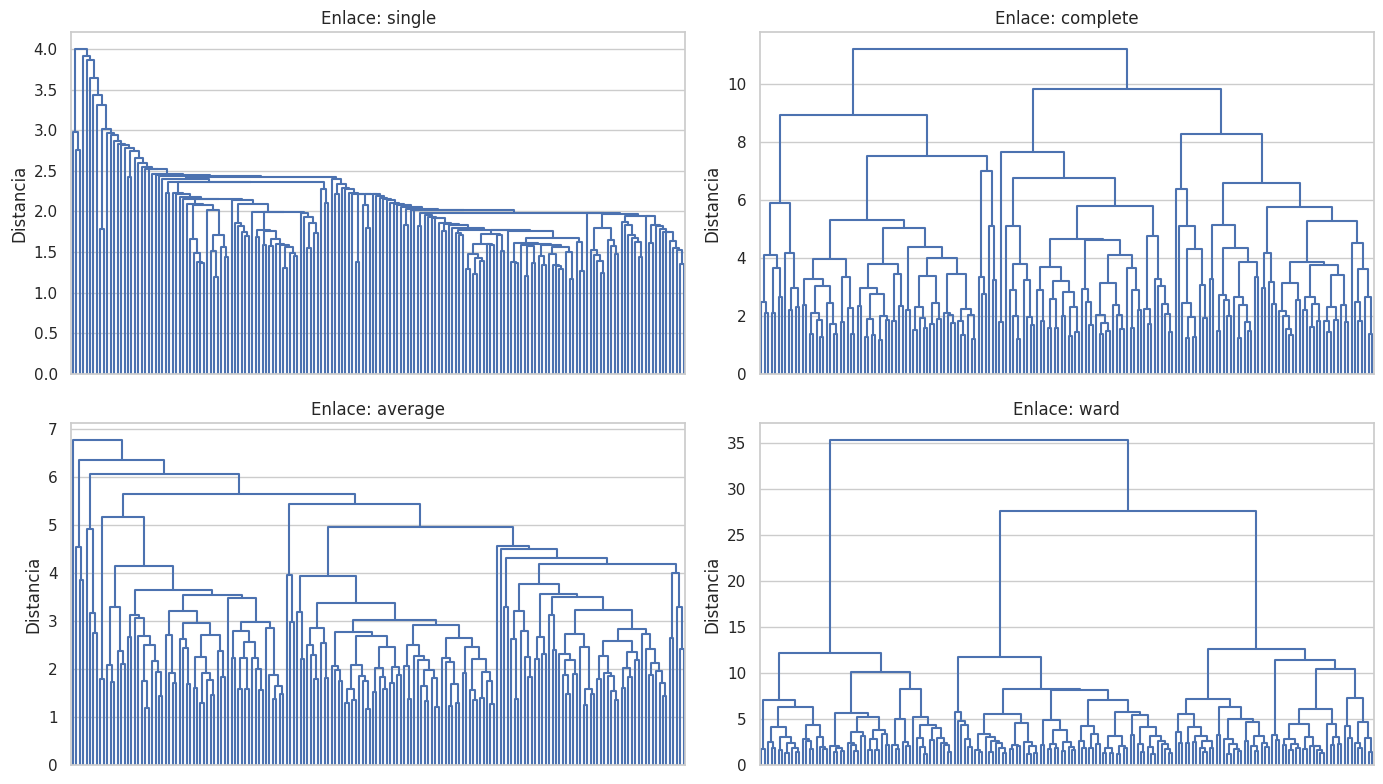

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (metodo, Z) in zip(axes.ravel(), enlaces.items()):
    dendrogram(Z, no_labels=True, ax=ax, color_threshold=0)
    ax.set_title(f'Enlace: {metodo}')
    ax.set_ylabel('Distancia')
plt.tight_layout()
plt.show()

**Pregunta 3.** ¿Qué diferencia observas en la forma de los dendrogramas? ¿Por qué el enlace simple produce "cadenas"?

Usamos **Ward** (minimiza el aumento de varianza intra-grupo) por producir grupos compactos y comparables con K-means.

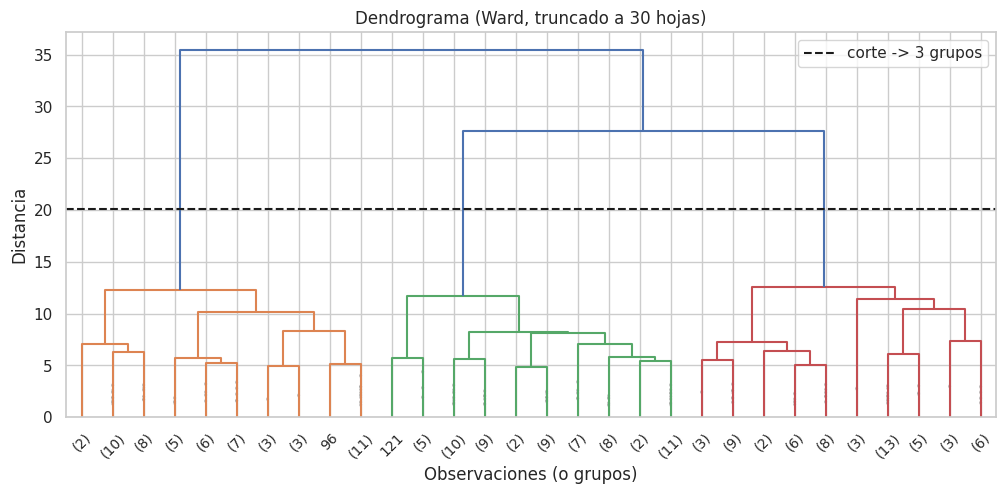

In [12]:
Z = enlaces['ward']

# Corte para obtener K grupos: se traza justo entre las dos últimas fusiones necesarias
altura_corte = (Z[-(K - 1), 2] + Z[-K, 2]) / 2 if K > 1 else Z[-1, 2] + 1

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_contracted=True,
           color_threshold=altura_corte, ax=ax)
ax.axhline(altura_corte, color='k', ls='--', label=f'corte -> {K} grupos')
ax.set(title='Dendrograma (Ward, truncado a 30 hojas)', xlabel='Observaciones (o grupos)', ylabel='Distancia')
ax.legend()
plt.show()

In [13]:
labels_h = fcluster(Z, t=K, criterion='maxclust') - 1   # 0..K-1
X_km['cluster_jerarquico'] = labels_h
X_km['cluster_jerarquico'].value_counts().sort_index().rename('n')

,n
cluster_jerarquico,
0,56
1,64
2,58


Otra pista para elegir el corte: **saltos grandes** en la altura de las últimas fusiones sugieren un buen número de grupos.

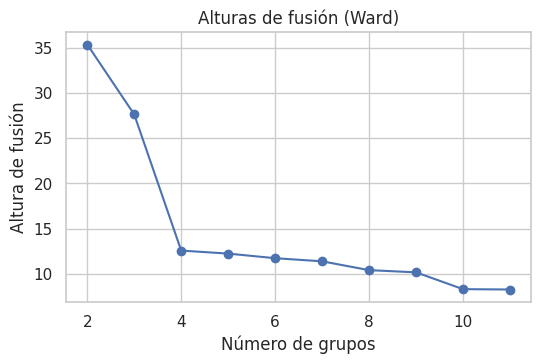

In [14]:
alturas = Z[-10:, 2][::-1]
plt.figure(figsize=(6, 3.5))
plt.plot(range(2, 12), alturas, 'o-')
plt.xlabel('Número de grupos'); plt.ylabel('Altura de fusión')
plt.title('Alturas de fusión (Ward)')
plt.show()

## 5. Visualización conjunta

### 5.1 Proyección PCA coloreada por cada método

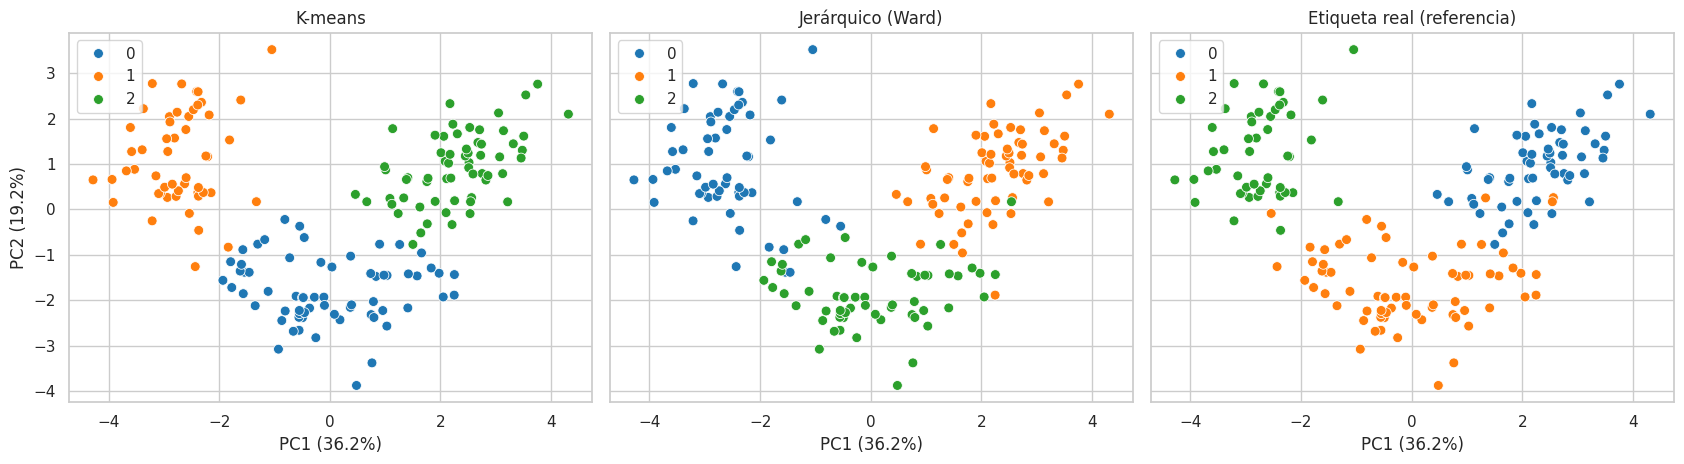

In [15]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Xs)
var = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, (col, tit) in zip(axes, [(kmeans.labels_, 'K-means'),
                                 (labels_h, 'Jerárquico (Ward)'),
                                 (y_real.values, 'Etiqueta real (referencia)')]):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=col, palette='tab10', s=50, ax=ax, legend='full')
    ax.set_title(tit)
    ax.set_xlabel(f'PC1 ({var[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({var[1]:.1f}%)')
plt.tight_layout()
plt.show()

### 5.2 Mapa de calor con dendrogramas (clustermap)

In [ ]:
colores = dict(zip(range(K), sns.color_palette('tab10', K)))
fila_col = pd.Series(labels_h, index=Xs.index).map(colores)

g = sns.clustermap(Xs, method='ward', metric='euclidean', cmap='vlag', center=0,
                   row_colors=fila_col, yticklabels=False, figsize=(11, 9),
                   cbar_kws={'label': 'z-score'})
g.fig.suptitle('Clustermap: observaciones y variables agrupadas (Ward)', y=1.02)
plt.show()

## 6. Comparación entre métodos

Tabla de contingencia y **Índice de Rand ajustado (ARI)**: 1 = particiones idénticas, ≈0 = acuerdo por azar.

In [ ]:
print('Contingencia K-means vs jerárquico')
display(pd.crosstab(X_km['cluster_kmeans'], X_km['cluster_jerarquico'],
                    rownames=['K-means'], colnames=['Jerárquico']))

print(f"ARI K-means vs jerárquico : {adjusted_rand_score(kmeans.labels_, labels_h):.3f}")
print(f"ARI K-means vs real       : {adjusted_rand_score(y_real, kmeans.labels_):.3f}")
print(f"ARI jerárquico vs real    : {adjusted_rand_score(y_real, labels_h):.3f}")
print(f"Silueta K-means / jerárquico: {silhouette_score(Xs, kmeans.labels_):.3f} / {silhouette_score(Xs, labels_h):.3f}")

## 7. Ejercicios

1. Repite el análisis **sin escalar** los datos. ¿Cómo cambian el codo, los grupos y el ARI? ¿Por qué?
2. Cambia `K` manualmente a 2, 4 y 5 y observa el dendrograma, el PCA y la silueta. ¿Cuál es más defendible?
3. Compara los enlaces `single`, `complete`, `average` y `ward` con `fcluster(..., criterion='maxclust')` para el mismo *K*. ¿Cuál se parece más a K-means?
4. Aplica todo el flujo a otro conjunto (p. ej. `ejercicios/data/afp_pep.csv` o `peptides.csv`; en este último, elimina `Class` y considera reducir dimensionalidad con PCA antes de agrupar).
5. Escribe 3-4 líneas interpretando los clusters usando el perfil de la sección 3. ¿Qué variables los distinguen?

## Cierre

- El **codo** da una pista de *k*, no una respuesta definitiva; apóyate en silueta, dendrograma y conocimiento del dominio.
- K-means necesita *k* de antemano y asume grupos compactos/esféricos; el jerárquico muestra toda la estructura y no requiere fijar *k* hasta el corte.
- Escalar y elegir bien las variables suele importar más que el algoritmo.